### Sesi 2 CNN dan Yolo <br>
By: Tegar Arifin Prasetyo

### Memeriksa ketersediaan GPU

Sebelum proses pengolahan gambar dan pelatihan model dimulai, lingkungan kerja perlu diperiksa terlebih dahulu. Perintah `nvidia-smi` menampilkan informasi kartu grafis NVIDIA yang tersedia, termasuk nama GPU, kapasitas memori, serta penggunaan memorinya. Informasi ini berguna karena pelatihan CNN dan YOLOv8 melibatkan banyak operasi perhitungan pada matriks gambar. Jika GPU tersedia dan telah dikenali oleh runtime, proses pelatihan biasanya dapat berjalan lebih cepat dibandingkan hanya menggunakan CPU. Jika perintah ini tidak menampilkan GPU, notebook tetap dapat dijalankan pada CPU, tetapi waktu pelatihannya mungkin lebih lama.

In [1]:
!nvidia-smi

Wed Nov 11 15:08:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.78                 KMD Version: 610.78        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   52C    P8              6W /   10W |       0MiB /   4096MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Mengunduh dataset klasifikasi kematangan pisang

Bagian ini menyiapkan dataset yang akan digunakan oleh model. Pertama, pustaka `roboflow` dipasang agar notebook dapat berkomunikasi dengan layanan Roboflow. Objek `Roboflow` kemudian dibuat menggunakan API key, lalu notebook memilih workspace dan project bernama `banana-ripeness-classification`. Versi dataset yang digunakan adalah versi 4. Perintah `download("folder")` mengunduh dataset dalam struktur folder yang dapat dibaca langsung oleh generator gambar Keras.

Setelah diunduh, folder validasi yang pada hasil unduhan bernama `valid` diubah namanya menjadi `val`. Penyesuaian ini dilakukan agar nama folder sesuai dengan variabel direktori yang digunakan pada bagian berikutnya. Dataset inilah yang menjadi sumber gambar untuk pelatihan dan validasi model.

**Catatan keamanan:** API key Roboflow adalah kredensial akses. Pada salinan notebook ini, nilai key diganti dengan teks pengganti. Masukkan API key milik sendiri melalui Colab Secrets atau variabel lingkungan sebelum menjalankan sel ini. Jangan membagikan notebook yang berisi API key aktif.

In [2]:
# Direktori dataset
import os
from types import SimpleNamespace

dataset_location = r"D:\Certan\week 10\Banana-Ripeness-Classification-4"
dataset = SimpleNamespace(location=dataset_location)

# Roboflow biasanya menggunakan nama folder "valid", sedangkan kode berikut memakai "val"
valid_folder = os.path.join(dataset.location, "valid")
val_folder = os.path.join(dataset.location, "val")

if os.path.isdir(valid_folder) and not os.path.isdir(val_folder):
    os.rename(valid_folder, val_folder)

print("Lokasi dataset:", dataset.location)
print("Folder train tersedia:", os.path.isdir(os.path.join(dataset.location, "train")))
print("Folder val tersedia:", os.path.isdir(val_folder))
print("Folder test tersedia:", os.path.isdir(os.path.join(dataset.location, "test")))


Lokasi dataset: D:\Certan\week 10\Banana-Ripeness-Classification-4
Folder train tersedia: True
Folder val tersedia: True
Folder test tersedia: True


### Menyiapkan gambar dan generator data

Setelah dataset tersedia, gambar perlu disiapkan agar dapat dibaca oleh model dengan format dan ukuran yang seragam. Variabel `train_dir` menunjuk ke folder gambar pelatihan, sedangkan `valid_dir` menunjuk ke folder validasi. Keduanya diambil dari lokasi dataset yang dikembalikan oleh Roboflow.

`ImageDataGenerator` digunakan untuk melakukan preprocessing sekaligus augmentasi. Pada data pelatihan, `rescale=1./255` mengubah rentang nilai piksel dari 0–255 menjadi 0–1. Augmentasi seperti rotasi, pergeseran posisi, shear, zoom, dan pembalikan horizontal membuat model melihat variasi gambar selama pelatihan. Tujuannya agar model tidak hanya menghafal posisi atau tampilan gambar tertentu, tetapi belajar mengenali ciri visual kematangan pisang pada variasi gambar yang berbeda.

Untuk data validasi, hanya dilakukan rescaling. Gambar validasi tidak perlu diubah secara acak karena fungsinya adalah mengukur kemampuan model pada data yang tidak digunakan untuk memperbarui bobot. Selanjutnya, `flow_from_directory` membaca gambar berdasarkan subfolder kelas. `target_size=(224, 224)` menyeragamkan ukuran gambar, `batch_size=32` menentukan jumlah gambar dalam satu batch, dan `class_mode='categorical'` menyiapkan label dalam bentuk one-hot encoding untuk klasifikasi empat kelas. Nama subfolder menjadi label kelas yang digunakan generator.

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Direktori dataset
train_dir = dataset.location + "/train"
valid_dir = dataset.location + "/val"
if not tf.io.gfile.exists(valid_dir):
    valid_dir = dataset.location + "/valid"

# Augmentasi data dan preprocessing
train_datagen = ImageDataGenerator(
    rescale=1./255,         # Normalisasi gambar
    rotation_range=20,      # Rotasi acak
    width_shift_range=0.2,  # Pergeseran horizontal
    height_shift_range=0.2, # Pergeseran vertikal
    shear_range=0.2,        # Perubahan sudut
    zoom_range=0.2,         # Zoom acak
    horizontal_flip=True    # Membalik gambar secara horizontal
)

# Untuk set validasi, kita hanya melakukan rescale
valid_datagen = ImageDataGenerator(rescale=1./255)

# Membuat data generator
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),   # Ubah ukuran gambar
    batch_size=32,
    class_mode='categorical'  # Klasifikasi multi-kelas
)

valid_generator = valid_datagen.flow_from_directory(
    valid_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)


Found 11793 images belonging to 4 classes.
Found 1123 images belonging to 4 classes.


### Membangun arsitektur CNN

Pada bagian ini dibuat model Convolutional Neural Network (CNN) menggunakan API `Sequential` dari Keras. Model disusun sebagai rangkaian lapisan yang diproses secara berurutan. CNN cocok untuk klasifikasi gambar karena lapisan konvolusi dapat mempelajari pola visual, mulai dari bentuk dan tepi sederhana hingga kombinasi pola yang lebih kompleks.

Tiga lapisan `Conv2D` menggunakan 32, 64, dan 128 filter berukuran 3×3. Setiap filter mempelajari pola tertentu pada gambar, sedangkan aktivasi `relu` membantu model mempelajari hubungan nonlinier. Setelah setiap konvolusi, `MaxPooling2D` dengan ukuran 2×2 mengecilkan dimensi fitur dengan mengambil nilai maksimum pada area kecil. Proses ini mengurangi jumlah perhitungan sekaligus mempertahankan fitur yang dianggap menonjol.

Keluaran lapisan konvolusi kemudian diratakan oleh `Flatten` menjadi vektor satu dimensi. Lapisan `Dense` dengan 128 neuron mempelajari kombinasi fitur untuk menentukan kelas. `Dropout(0.5)` menonaktifkan sebagian neuron secara acak ketika pelatihan untuk membantu mengurangi overfitting. Lapisan terakhir memiliki empat neuron dengan aktivasi `softmax`, sesuai empat kategori kematangan pisang pada dataset. Softmax menghasilkan nilai probabilitas untuk setiap kelas.

Model dikompilasi dengan optimizer `adam`, fungsi loss `categorical_crossentropy`, dan metrik `accuracy`. Optimizer memperbarui bobot model, loss mengukur kesalahan prediksi untuk label kategorikal, sedangkan accuracy mencatat proporsi prediksi yang benar. `model.summary()` menampilkan susunan lapisan dan jumlah parameter yang akan dipelajari.

In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Membangun model CNN
model = Sequential()

# Lapisan Convolutional pertama
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Lapisan Convolutional kedua
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Lapisan Convolutional ketiga
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Lapisan Flatten
model.add(Flatten())

# Fully Connected Layer
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))  # Dropout untuk mencegah overfitting

# Lapisan Output
model.add(Dense(4, activation='softmax'))  # 4 kelas untuk kematangan pisang

# Kompilasi model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Menampilkan ringkasan model
model.summary()

c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

### Melatih model CNN

`model.fit()` menjalankan proses pembelajaran menggunakan gambar dari `train_generator`. Pada setiap batch, model membuat prediksi, menghitung nilai loss, lalu memperbarui bobot agar kesalahan prediksi berkurang. `steps_per_epoch` menentukan jumlah batch yang diproses dalam satu epoch; pada kode ini nilainya dihitung dari jumlah sampel pelatihan dibagi ukuran batch.

`validation_data` memberikan data validasi untuk memantau performa model setelah setiap epoch. `validation_steps` menentukan jumlah batch validasi yang diproses. Parameter `epochs=9` berarti seluruh data pelatihan akan dilalui hingga sembilan kali sesuai jumlah langkah yang ditentukan. Hasil proses pelatihan disimpan pada variabel `history`, sehingga nilai akurasi dan loss tiap epoch dapat digunakan untuk membuat grafik pada bagian selanjutnya.

In [5]:
# Melatih model
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=valid_generator,
    validation_steps=valid_generator.samples // valid_generator.batch_size,
    epochs=9  # Jumlah epoch
)


Epoch 1/9
368/368 ━━━━━━━━━━━━━━━━━━━━ 536s 1s/step - accuracy: 0.6253 - loss: 0.8839 - val_accuracy: 0.8420 - val_loss: 0.4022
Epoch 2/9
  1/368 ━━━━━━━━━━━━━━━━━━━━ 3:56 643ms/step - accuracy: 0.7188 - loss: 0.6215

c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


368/368 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.7188 - loss: 0.6215 - val_accuracy: 0.8562 - val_loss: 0.4015
Epoch 3/9
368/368 ━━━━━━━━━━━━━━━━━━━━ 458s 1s/step - accuracy: 0.8254 - loss: 0.4550 - val_accuracy: 0.8429 - val_loss: 0.4627
Epoch 4/9
368/368 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.7188 - loss: 0.6553 - val_accuracy: 0.8027 - val_loss: 0.5397
Epoch 5/9
368/368 ━━━━━━━━━━━━━━━━━━━━ 413s 1s/step - accuracy: 0.8550 - loss: 0.3949 - val_accuracy: 0.8607 - val_loss: 0.5476
Epoch 6/9
368/368 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9062 - loss: 0.3973 - val_accuracy: 0.8652 - val_loss: 0.5414
Epoch 7/9
368/368 ━━━━━━━━━━━━━━━━━━━━ 366s 994ms/step - accuracy: 0.8759 - loss: 0.3477 - val_accuracy: 0.9232 - val_loss: 0.2388
Epoch 8/9
368/368 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8125 - loss: 0.3910 - val_accuracy: 0.9268 - val_loss: 0.2256
Epoch 9/9
368/368 ━━━━━━━━━━━━━━━━━━━━ 390s 1s/step - accuracy: 0.8752 - loss: 0.3542 - val_accuracy: 0.8973 - 

### Mengevaluasi hasil klasifikasi CNN

Setelah pelatihan selesai, model dievaluasi menggunakan data validasi. `model.evaluate()` menghasilkan nilai loss dan accuracy pada data tersebut. Loss menunjukkan besar kesalahan prediksi menurut fungsi loss yang digunakan saat kompilasi, sedangkan accuracy menunjukkan proporsi gambar yang diprediksi dengan benar.

Berikutnya, `model.predict()` menghasilkan skor prediksi untuk setiap kelas. `argmax` memilih indeks kelas dengan skor tertinggi sebagai hasil prediksi. Label sebenarnya diambil dari `valid_generator.classes`. `classification_report` merangkum precision, recall, dan F1-score untuk setiap kelas. Precision menunjukkan seberapa banyak prediksi suatu kelas yang benar; recall menunjukkan seberapa banyak data sebenarnya dari kelas itu yang berhasil ditemukan; F1-score merupakan rata-rata harmonis precision dan recall.

`confusion_matrix` membandingkan label sebenarnya dengan label prediksi. Nilai pada diagonal menunjukkan prediksi benar, sedangkan nilai di luar diagonal menunjukkan kelas yang tertukar. Bagian visualisasi menggunakan `imshow` untuk menampilkan matriks dalam bentuk gambar, menambahkan skala warna, serta memberi label kelas pada sumbu. Dengan demikian, evaluasi tidak hanya bergantung pada satu angka accuracy, tetapi juga memperlihatkan kelas mana yang mudah atau sulit dikenali.

Perlu diperhatikan bahwa `flow_from_directory` secara default dapat mengacak urutan gambar. Karena kode mengambil `valid_generator.classes` setelah melakukan prediksi, urutan prediksi dan label sebenarnya perlu dipastikan sama. Untuk evaluasi yang benar-benar selaras, generator validasi sebaiknya dibuat dengan `shuffle=False` sejak awal. Kode asli di bawah tetap dipertahankan agar alur praktikum tidak berubah.

36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 142ms/step - accuracy: 0.8967 - loss: 0.2779
Validation Loss: 0.2779429256916046
Validation Accuracy: 0.8967052698135376
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 129ms/step
              precision    recall  f1-score   support

           0       0.22      0.17      0.20       229
           1       0.33      0.35      0.34       339
           2       0.36      0.38      0.37       388
           3       0.16      0.16      0.16       167

    accuracy                           0.30      1123
   macro avg       0.27      0.27      0.27      1123
weighted avg       0.29      0.30      0.29      1123



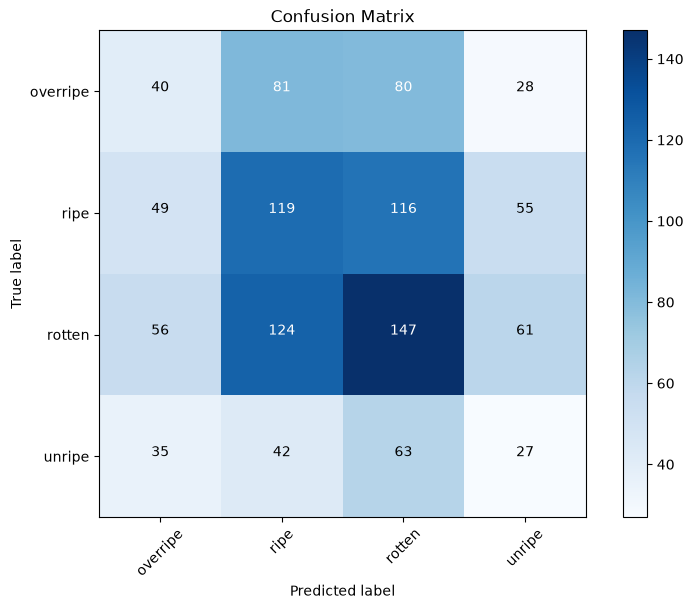

In [8]:
# Model evaluation using precision, recall, confusion matrix and f1 score, display confusion matrix in plt

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Evaluasi model pada keseluruhan class data validasi
val_loss, val_accuracy = model.evaluate(valid_generator)
print(f"Validation Loss: {val_loss}")
print(f"Validation Accuracy: {val_accuracy}")

# Evaluasi model pada setiap class data validasi
valid_generator.reset()
y_pred = model.predict(valid_generator)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = valid_generator.classes

# Menghitung metrik evaluasi
report = classification_report(y_true, y_pred_classes)
print(report)

# Membuat confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Menampilkan confusion matrix
plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(valid_generator.class_indices))
plt.xticks(tick_marks, valid_generator.class_indices, rotation=45)
plt.yticks(tick_marks, valid_generator.class_indices)

# Menambahkan label pada setiap sel
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.tight_layout()
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

### Melihat grafik akurasi dan loss

Variabel `history` yang dihasilkan oleh `model.fit()` menyimpan catatan performa model pada setiap epoch. Grafik pertama membandingkan `accuracy` pada data pelatihan dengan `val_accuracy` pada data validasi. Jika keduanya meningkat dan nilainya relatif berdekatan, model cenderung belajar dengan baik. Jika akurasi pelatihan terus meningkat sementara akurasi validasi tertahan atau menurun, hal tersebut dapat menjadi tanda overfitting.

Grafik kedua membandingkan `loss` pelatihan dengan `val_loss`. Loss yang menurun menunjukkan kesalahan model semakin kecil. Perbedaan yang semakin lebar antara loss pelatihan dan validasi juga dapat menjadi indikasi bahwa model terlalu menyesuaikan diri pada data pelatihan. Grafik ini membantu membaca pola pembelajaran, bukan hanya melihat hasil akhir.

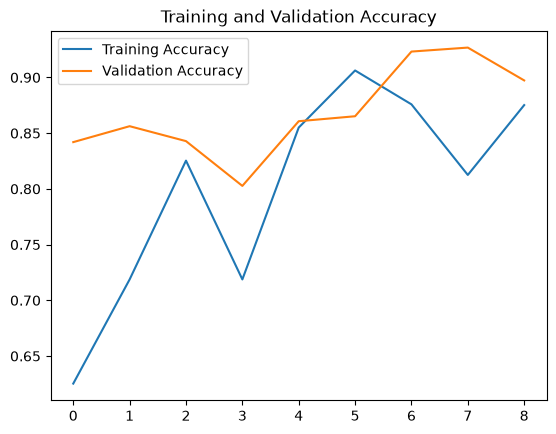

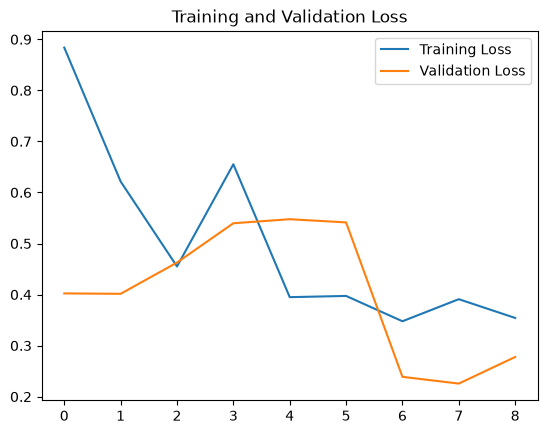

In [9]:
import matplotlib.pyplot as plt

# Visualisasi akurasi
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

# Visualisasi loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()


### Menguji prediksi CNN pada satu gambar

Fungsi `predict_image()` dibuat agar model dapat diuji pada satu file gambar di luar alur batch generator. `load_img` membuka gambar dan mengubah ukurannya menjadi 224×224 piksel, sama seperti ukuran masukan saat pelatihan. `img_to_array` mengubah gambar menjadi array numerik, lalu `expand_dims` menambahkan dimensi batch karena model mengharapkan masukan berbentuk kumpulan gambar, meskipun hanya satu gambar yang diproses.

Array piksel dibagi 255 agar nilainya berada pada rentang 0–1, konsisten dengan preprocessing saat pelatihan. Model kemudian menghasilkan skor untuk empat kelas. `argmax` memilih kelas dengan skor terbesar, sedangkan daftar label diambil dari `train_generator.class_indices`. Terakhir, gambar ditampilkan dan judulnya diisi dengan kelas hasil prediksi. Baris contoh pemanggilan fungsi menggunakan satu gambar dari folder `test/ripe`; hasilnya dapat digunakan untuk melihat apakah model mengenali gambar tersebut sebagai pisang matang. Hasil satu gambar saja belum cukup untuk menyimpulkan performa keseluruhan model.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step


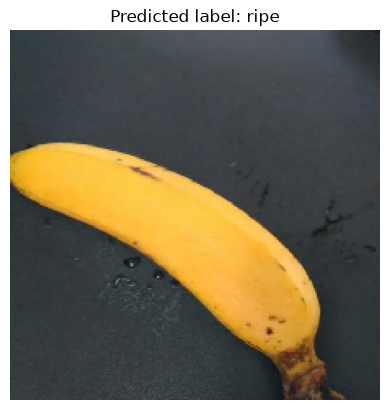

In [10]:
# inference using model, and add text to displayed predict image

from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import numpy as np
import glob
import os

def predict_image(image_path):
  img = image.load_img(image_path, target_size=(224, 224))
  img_array = image.img_to_array(img)
  img_array = np.expand_dims(img_array, axis=0)
  img_array /= 255.

  prediction = model.predict(img_array)
  predicted_class = np.argmax(prediction)

  # Get class labels from the generator
  class_labels = list(train_generator.class_indices.keys())

  # Display the image with prediction
  plt.imshow(img)
  plt.title(f"Predicted label: {class_labels[predicted_class]}")
  plt.axis('off')
  plt.show()

# Example usage
image_files = glob.glob(os.path.join(dataset.location, "test", "ripe", "*"))
if image_files:
  image_path = image_files[0]
  predict_image(image_path)
else:
  print("Gambar pada folder test/ripe tidak ditemukan.")


# YOLOv8 Transfer Learning

## Install YOLOv8

### Memasang dan memeriksa Ultralytics YOLOv8

Bagian berikutnya beralih dari model CNN yang dibangun sendiri ke YOLOv8 dari pustaka Ultralytics. Perintah `pip install ultralytics` memasang paket yang menyediakan implementasi model YOLO beserta antarmuka perintah `yolo`. `display.clear_output()` membersihkan keluaran instalasi agar tampilan notebook lebih rapi. Setelah itu, pustaka `ultralytics` diimpor dan `ultralytics.checks()` dijalankan untuk memeriksa lingkungan serta dependensi yang diperlukan.

Pada praktikum ini, YOLOv8 digunakan dalam mode *classification* (`task=classify`), bukan deteksi objek dengan kotak pembatas. Karena itu, keluaran model berupa prediksi kategori gambar.

In [11]:
# Pip install method (recommended)

!pip install ultralytics

from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics 8.4.208  Python-3.14.7 torch-2.15.0+cpu CPU (11th Gen Intel Core i5-11400H @ 2.70GHz)
Setup complete  (12 CPUs, 7.7 GB RAM, 47.6/125.0 GB disk)


## Inference with Pre-trained COCO Model

### Mencoba model klasifikasi YOLOv8 yang telah dilatih sebelumnya

Perintah ini menjalankan inferensi menggunakan bobot `yolov8x-cls.pt`, yaitu model YOLOv8 varian besar untuk klasifikasi yang bobot awalnya telah dilatih sebelumnya. `mode=predict` berarti model digunakan untuk membuat prediksi, bukan melatih ulang. `conf=0.25` menentukan ambang kepercayaan yang diminta pada prediksi, sedangkan `source` menunjuk ke gambar anjing yang diambil dari alamat contoh Roboflow.

Contoh ini berfungsi untuk memastikan model klasifikasi pralatih dapat dijalankan dan memperlihatkan alur inferensi. Gambar anjing tersebut bukan bagian dari dataset pisang, sehingga hasilnya tidak boleh dianggap sebagai hasil klasifikasi kematangan pisang. Model khusus pisang baru dilatih pada bagian *custom training*.

In [12]:
!yolo task=classify mode=predict model=yolov8x-cls.pt conf=0.25 source='https://media.roboflow.com/notebooks/examples/dog.jpeg'

Ultralytics 8.4.208  Python-3.14.7 torch-2.15.0+cpu CPU (11th Gen Intel Core i5-11400H @ 2.70GHz)
YOLOv8x-cls summary (fused): 54 layers, 57,404,200 parameters, 0 gradients, 153.8 GFLOPs

Found https://media.roboflow.com/notebooks/examples/dog.jpeg locally at dog.jpeg
image 1/1 d:\Certan\week 10\dog.jpeg: 224x224 beagle 0.69, Walker_hound 0.12, basset 0.10, English_foxhound 0.06, bloodhound 0.01, 134.5ms
Speed: 19.1ms preprocess, 134.5ms inference, 1.6ms postprocess per image at shape (1, 3, 224, 224)
Results saved to D:\Certan\week 10\runs\classify\predict-4
 Learn more at https://docs.ultralytics.com/modes/predict


### Menampilkan hasil inferensi model pralatih

Perintah sebelumnya menyimpan hasil prediksi ke direktori keluaran YOLO. Kode ini menggunakan `Image` dari IPython untuk menampilkan file gambar hasil inferensi tersebut di notebook dengan tinggi tampilan 600 piksel. Tampilan ini membantu memeriksa hasil yang disimpan oleh proses prediksi. Nama dan lokasi file mengikuti direktori keluaran yang dibuat Ultralytics; apabila direktori prediksi sudah pernah dibuat sebelumnya, nomor folder keluaran dapat berubah.

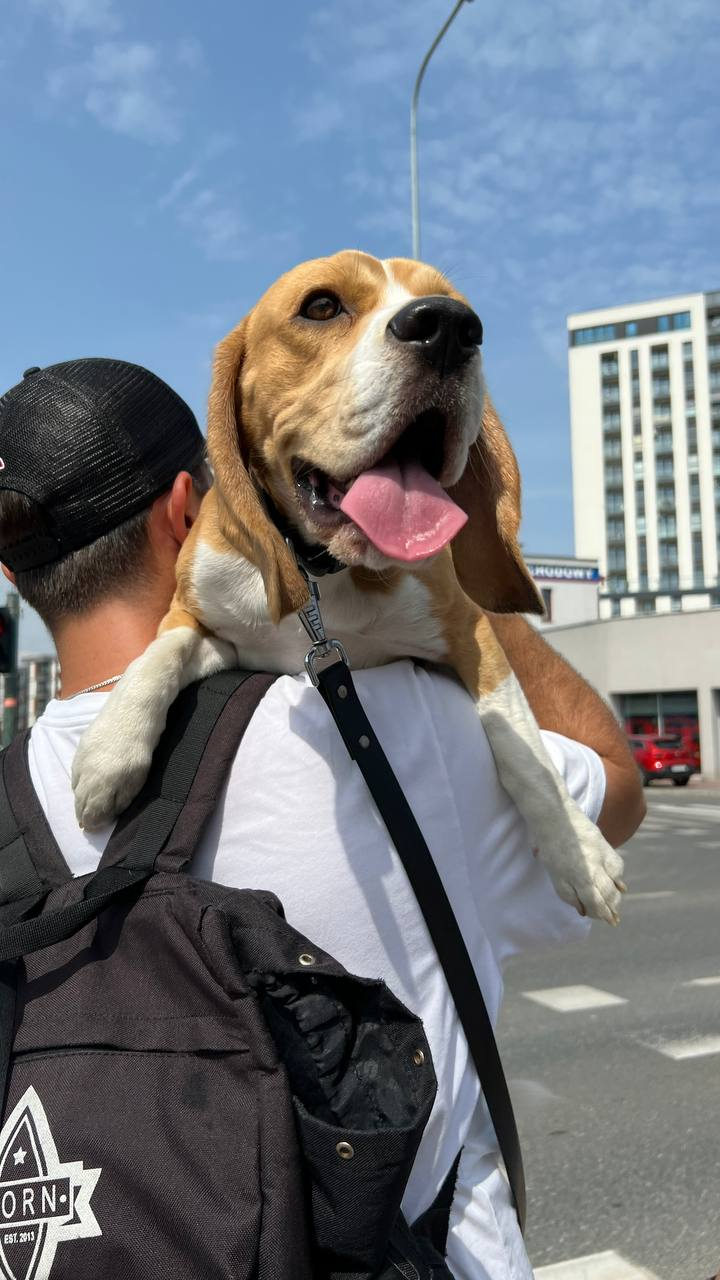

In [16]:
from IPython.display import Image
Image(filename='dog.jpeg', height=600)

## Custom Training

### Melatih YOLOv8 menggunakan dataset kematangan pisang

Di sini model YOLOv8 klasifikasi pralatih digunakan sebagai titik awal untuk mempelajari dataset pisang. `task=classify` menetapkan tugas klasifikasi gambar, sedangkan `mode=train` menjalankan pelatihan. Parameter `model=yolov8x-cls.pt` memilih bobot awal model. `data={dataset.location}` mengarahkan Ultralytics ke direktori dataset yang sebelumnya diunduh dari Roboflow. Struktur dataset klasifikasi biasanya berisi folder train, val, dan test, dengan subfolder untuk setiap kelas.

`epochs=5` menetapkan lima putaran pelatihan, `imgsz=224` menentukan ukuran gambar masukan, dan `batch=32` menentukan jumlah gambar dalam satu batch. `freeze=5` membekukan lima lapisan awal agar sebagian fitur yang telah dipelajari model pralatih tetap dipertahankan sementara lapisan lainnya menyesuaikan diri dengan dataset pisang. Setelah proses ini selesai, Ultralytics menyimpan bobot hasil pelatihan, termasuk bobot terbaik (`best.pt`) yang digunakan untuk validasi dan prediksi berikutnya.

In [1]:
!yolo task=classify mode=train model=yolov8n-cls.pt data="{dataset.location}" epochs=5 imgsz=224 batch=32 freeze=5 project=runs/classify name=train exist_ok=True

New https://pypi.org/project/ultralytics/8.4.210 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.208  Python-3.14.7 torch-2.15.0+cpu CPU (11th Gen Intel Core i5-11400H @ 2.70GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data={dataset.location}, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=5, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, moment

Traceback (most recent call last):
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\engine\trainer.py", line 867, in get_dataset
    data = check_cls_dataset(self.args.data, split=self.args.split)
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\data\utils.py", line 882, in check_cls_dataset
    raise ValueError(
    ...<2 lines>...
    )
ValueError: Classification datasets must be a directory (data="path/to/dir") not a file (data="{dataset.location}"), See https://docs.ultralytics.com/datasets/classify

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\msii\AppData\Local\Programs\Python\Python314\Scripts\yolo.exe\__main__.py", line 5, in <module>
    sys.exit(entrypoint())
             ~~~~~~~~~~^^
  File "c:\Users\msii\AppDat

### Menampilkan grafik hasil pelatihan YOLOv8

Selama pelatihan, Ultralytics menyimpan ringkasan metrik dan grafik ke folder hasil eksperimen. Kode ini menampilkan file `results.png` dari direktori `runs/classify/train`. Grafik tersebut biasanya merangkum perubahan metrik pelatihan dan validasi selama epoch, misalnya loss dan accuracy/top-1 atau top-5 accuracy sesuai tugas klasifikasi. Grafik dapat digunakan untuk melihat apakah performa membaik selama pelatihan dan apakah terdapat perbedaan antara data pelatihan dan validasi.

Lokasi file ditulis secara langsung sebagai `/content/runs/classify/train/results.png`, sehingga kode ini mengasumsikan notebook dijalankan di Google Colab dan hasil eksperimen berada di lokasi tersebut.

In [2]:
from IPython.display import Image, display
import os

result_image = os.path.join("runs", "classify", "train", "results.png")
if os.path.exists(result_image):
    display(Image(filename=result_image, width=750))
else:
    print("File results.png belum ditemukan. Jalankan pelatihan YOLO terlebih dahulu.")


File results.png belum ditemukan. Jalankan pelatihan YOLO terlebih dahulu.


## Validate Custom Model

### Memvalidasi model YOLOv8 yang telah dilatih

Perintah ini menjalankan evaluasi model khusus pisang pada data validasi. `mode=val` memilih proses validasi, `model` menunjuk ke bobot terbaik hasil pelatihan (`best.pt`), dan `data={dataset.location}` menunjuk ke dataset yang sama. Validasi digunakan untuk mengukur kemampuan model pada data yang tidak dipakai untuk memperbarui bobot selama pelatihan. Hasilnya dapat dipakai untuk menilai apakah model mampu menggeneralisasi pola visual dari data pelatihan ke gambar validasi.

In [3]:
!yolo task=classify mode=val model="runs/classify/train/weights/best.pt" data="{dataset.location}" project=runs/classify name=val exist_ok=True

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\msii\AppData\Local\Programs\Python\Python314\Scripts\yolo.exe\__main__.py", line 5, in <module>
    sys.exit(entrypoint())
             ~~~~~~~~~~^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\cfg\__init__.py", line 1163, in entrypoint
    model = YOLO(model, task=task)
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\models\yolo\model.py", line 84, in __init__
    super().__init__(model=model, task=task, verbose=verbose)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\engine\model.py", line 140, in __init__
    self._load(model, task=task)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\

### Melihat confusion matrix hasil validasi YOLOv8

Ultralytics menyimpan confusion matrix sebagai gambar pada folder validasi. Baris ini menampilkan `confusion_matrix_normalized.png`, yaitu confusion matrix yang nilainya telah dinormalisasi. Matriks membantu melihat hubungan antara kelas sebenarnya dan kelas yang diprediksi. Nilai pada diagonal menunjukkan kecenderungan prediksi yang benar, sedangkan nilai di luar diagonal menunjukkan pasangan kelas yang masih sering tertukar.

Karena matriks telah dinormalisasi, nilainya umumnya dibaca sebagai proporsi, bukan jumlah gambar mentah. File ini baru tersedia setelah perintah validasi berhasil dijalankan.

In [4]:
import os
from IPython.display import Image, display

confusion_image = os.path.join("runs", "classify", "val", "confusion_matrix_normalized.png")
if os.path.exists(confusion_image):
    display(Image(filename=confusion_image, width=750))
else:
    print("File confusion_matrix_normalized.png belum ditemukan. Jalankan validasi YOLO terlebih dahulu.")


File confusion_matrix_normalized.png belum ditemukan. Jalankan validasi YOLO terlebih dahulu.


## Inference menggunakan Custom Model

### Memprediksi gambar pada kelas overripe

Perintah ini menggunakan bobot `best.pt` hasil pelatihan khusus pisang untuk memprediksi gambar yang berada pada folder `test/overripe`. `mode=predict` menjalankan inferensi, `conf=0.25` menetapkan ambang confidence, dan `source` menentukan folder gambar yang akan diproses. Folder sumber dipilih secara khusus agar hasil prediksi untuk kelas *overripe* dapat diperiksa. Nama folder menunjukkan label data sebenarnya, sedangkan kelas keluaran tetap ditentukan oleh model berdasarkan isi gambar.

In [5]:
!yolo task=classify mode=predict model="runs/classify/train/weights/best.pt" conf=0.25 source="{dataset.location}/test/overripe"

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\msii\AppData\Local\Programs\Python\Python314\Scripts\yolo.exe\__main__.py", line 5, in <module>
    sys.exit(entrypoint())
             ~~~~~~~~~~^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\cfg\__init__.py", line 1163, in entrypoint
    model = YOLO(model, task=task)
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\models\yolo\model.py", line 84, in __init__
    super().__init__(model=model, task=task, verbose=verbose)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\engine\model.py", line 140, in __init__
    self._load(model, task=task)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\

### Memprediksi gambar pada kelas ripe

Kode ini menjalankan prediksi pada folder `test/ripe` menggunakan bobot terbaik dari pelatihan YOLOv8. Tujuannya adalah memeriksa bagaimana model mengenali contoh pisang pada kategori *ripe* atau matang. Dengan menguji setiap folder kelas secara terpisah, hasil prediksi dapat dibandingkan dengan label folder sumber untuk melihat kelas mana yang sudah dikenali dengan baik dan kelas mana yang masih berpotensi tertukar.

In [6]:
!yolo task=classify mode=predict model="runs/classify/train/weights/best.pt" conf=0.25 source="{dataset.location}/test/ripe"

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\msii\AppData\Local\Programs\Python\Python314\Scripts\yolo.exe\__main__.py", line 5, in <module>
    sys.exit(entrypoint())
             ~~~~~~~~~~^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\cfg\__init__.py", line 1163, in entrypoint
    model = YOLO(model, task=task)
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\models\yolo\model.py", line 84, in __init__
    super().__init__(model=model, task=task, verbose=verbose)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\engine\model.py", line 140, in __init__
    self._load(model, task=task)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\

### Memprediksi gambar pada kelas rotten

Bagian ini menjalankan inferensi pada gambar yang tersimpan di folder `test/rotten`. Model tetap menggunakan bobot `best.pt` yang sama, sehingga perbedaan hasil prediksi berasal dari gambar yang diuji, bukan dari model yang berbeda. Hasil pada kelas *rotten* dapat diamati untuk menilai apakah ciri visual pisang yang busuk berhasil dibedakan dari kategori lainnya.

In [7]:
!yolo task=classify mode=predict model="runs/classify/train/weights/best.pt" conf=0.25 source="{dataset.location}/test/rotten"

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\msii\AppData\Local\Programs\Python\Python314\Scripts\yolo.exe\__main__.py", line 5, in <module>
    sys.exit(entrypoint())
             ~~~~~~~~~~^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\cfg\__init__.py", line 1163, in entrypoint
    model = YOLO(model, task=task)
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\models\yolo\model.py", line 84, in __init__
    super().__init__(model=model, task=task, verbose=verbose)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\engine\model.py", line 140, in __init__
    self._load(model, task=task)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\

### Memprediksi gambar pada kelas unripe

Perintah ini menguji gambar pada folder `test/unripe`, yaitu kategori pisang yang belum matang. Pengaturan model dan confidence sama dengan pengujian folder sebelumnya. Pengujian per kelas membantu memberikan gambaran yang lebih rinci daripada hanya menjalankan prediksi pada satu gambar, meskipun penilaian akhir tetap perlu mengacu pada metrik validasi dan pemeriksaan label setiap gambar.

In [8]:
!yolo task=classify mode=predict model="runs/classify/train/weights/best.pt" conf=0.25 source="{dataset.location}/test/unripe"

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\msii\AppData\Local\Programs\Python\Python314\Scripts\yolo.exe\__main__.py", line 5, in <module>
    sys.exit(entrypoint())
             ~~~~~~~~~~^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\cfg\__init__.py", line 1163, in entrypoint
    model = YOLO(model, task=task)
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\models\yolo\model.py", line 84, in __init__
    super().__init__(model=model, task=task, verbose=verbose)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\ultralytics\engine\model.py", line 140, in __init__
    self._load(model, task=task)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\

### Menampilkan beberapa hasil prediksi dari folder pertama

Setelah perintah prediksi YOLOv8 dijalankan, hasil gambar disimpan ke folder keluaran seperti `runs/classify/predict2`. `glob.glob()` mencari file JPG pada folder tersebut. Ekspresi `[:3]` membatasi tampilan hingga tiga gambar pertama agar keluaran notebook tidak terlalu panjang. `display(Image(...))` kemudian menampilkan setiap gambar dengan lebar 600 piksel.

Folder `predict2` umumnya merupakan direktori hasil prediksi berikutnya setelah folder `predict` digunakan pada contoh model pralatih. Penomoran folder dapat berubah jika perintah prediksi dijalankan berulang kali; jika gambar tidak ditemukan, periksa nama folder hasil yang dibuat Ultralytics.

In [9]:
import glob
import os
from IPython.display import Image, display

for image_path in glob.glob(os.path.join("runs", "classify", "predict2", "*.jpg"))[:3]:
      display(Image(filename=image_path, width=600))


### Menampilkan beberapa hasil prediksi dari folder keluaran berikutnya

Kode ini memiliki tujuan yang sama dengan bagian sebelumnya, tetapi membaca gambar dari direktori `runs/classify/predict3`. Daftar file JPG diambil menggunakan `glob`, kemudian maksimal tiga gambar ditampilkan. Pemisahan berdasarkan direktori keluaran memungkinkan hasil dari beberapa perintah prediksi dilihat secara terpisah. Pastikan direktori tersebut memang dibuat oleh eksekusi sebelumnya karena nomor folder dapat berubah saat notebook dijalankan ulang.

In [10]:
import glob
import os
from IPython.display import Image, display

for image_path in glob.glob(os.path.join("runs", "classify", "predict3", "*.jpg"))[:3]:
      display(Image(filename=image_path, width=600))


### Menampilkan hasil prediksi dari direktori predict4

Pada bagian ini notebook mencari hingga tiga file JPG di direktori `runs/classify/predict4`, lalu menampilkannya satu per satu. Gambar yang terlihat merupakan keluaran inferensi yang disimpan YOLOv8, sehingga dapat digunakan untuk memeriksa hasil klasifikasi pada sampel gambar. Jika tidak ada gambar yang muncul, kemungkinan nama direktori tidak sesuai dengan nomor eksperimen yang terbentuk pada sesi tersebut.

In [11]:
import glob
import os
from IPython.display import Image, display

for image_path in glob.glob(os.path.join("runs", "classify", "predict4", "*.jpg"))[:3]:
      display(Image(filename=image_path, width=600))


### Menampilkan hasil prediksi dari direktori predict5

Sel terakhir menampilkan maksimal tiga gambar dari direktori `runs/classify/predict5`. Dengan menampilkan sampel hasil prediksi dari beberapa folder keluaran, hasil inferensi untuk kategori-kategori pengujian dapat diamati secara visual. Perlu diingat bahwa nomor `predict2` sampai `predict5` bergantung pada urutan eksekusi perintah dan dapat berbeda jika notebook dijalankan ulang atau direktori hasil sebelumnya sudah ada.

In [12]:
import glob
import os
from IPython.display import Image, display

for image_path in glob.glob(os.path.join("runs", "classify", "predict5", "*.jpg"))[:3]:
      display(Image(filename=image_path, width=600))


**Tugas** <br>

Silahkan jelaskan secara rinci kode program dan hasilnya (hint: lihat slide sesi teori ada gambaran secara umum, di tugas ini kalian detailkan maksud dan tujuannya), dikumpulkan paling lambat Rabu, 11 November 2026 jam 23.59 di ecourse